In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../dataset/food_delivery.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (45584, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Columns:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  str    
 1   Delivery_person_ID           45584 non-null  str    
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,45584,45584,0xcdcd,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_ID,45584,1320,JAPRES11DEL02,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_Age,43730.0,NaN,NaN,NaN,29.566911,5.815064,15.0,25.0,30.0,35.0,50.0
Delivery_person_Ratings,43676.0,NaN,NaN,NaN,4.633774,0.334744,1.0,4.5,4.7,4.9,6.0
Restaurant_latitude,45584.0,NaN,NaN,NaN,17.017948,8.185674,-30.905562,12.933284,18.55144,22.728163,30.914057
Restaurant_longitude,45584.0,NaN,NaN,NaN,70.229684,22.885575,-88.366217,73.17,75.897963,78.044095,88.433452
Delivery_location_latitude,45584.0,NaN,NaN,NaN,17.46548,7.335562,0.01,12.988453,18.633934,22.785049,31.054057
Delivery_location_longitude,45584.0,NaN,NaN,NaN,70.844161,21.120578,0.01,73.28,76.002574,78.107044,88.563452
Order_Date,45584,44,15-03-2022,1192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_Orderd,43853,176,21:55,461,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


Delivery_person_Ratings        1908
Delivery_person_Age            1854
Time_Orderd                    1731
City                           1200
multiple_deliveries             993
Weather_conditions              616
Road_traffic_density            601
Festival                        228
ID                                0
Type_of_vehicle                   0
Type_of_order                     0
Vehicle_condition                 0
Time_Order_picked                 0
Delivery_person_ID                0
Order_Date                        0
Delivery_location_longitude       0
Delivery_location_latitude        0
Restaurant_longitude              0
Restaurant_latitude               0
Time_taken (min)                  0
dtype: int64


Duplicate rows: 0


In [5]:
required_columns = [
    "Time_taken(min)",
    "Order_Date",
    "Time_Orderd",
    "Time_Order_picked",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"These expected columns are missing: {missing_columns}"
    )

print("Required columns found.")

ValueError: These expected columns are missing: ['Time_taken(min)']

In [6]:
print(df.columns.tolist())

['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)']


In [7]:
required_columns = [
    "Time_taken (min)",
    "Order_Date",
    "Time_Orderd",
    "Time_Order_picked",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"These expected columns are missing: {missing_columns}"
    )

print("Required columns found.")

Required columns found.


In [9]:
df.columns = df.columns.str.strip()

df = df.replace(
    ["NaN", "nan", "NULL", "null", "None", ""],
    np.nan
)

print(df.isnull().sum())

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weather_conditions              616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken (min)                  0
dtype: int64


In [10]:
print("Before:", df.shape)

df = df.drop_duplicates()

print("After:", df.shape)

Before: (45584, 20)
After: (45584, 20)


In [11]:
numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries",
    "Time_taken(min)"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

KeyError: 'Time_taken(min)'

In [12]:
numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries",
    "Time_taken (min)"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Numeric columns converted successfully.")

Numeric columns converted successfully.


In [13]:
# Invalid ages
df.loc[
    (df["Delivery_person_Age"] < 18) |
    (df["Delivery_person_Age"] > 70),
    "Delivery_person_Age"
] = np.nan

# Ratings must be between 1 and 5
df.loc[
    (df["Delivery_person_Ratings"] < 1) |
    (df["Delivery_person_Ratings"] > 5),
    "Delivery_person_Ratings"
] = np.nan

# Vehicle condition must be in the dataset's valid range
df.loc[
    ~df["Vehicle_condition"].isin([0, 1, 2, 3]),
    "Vehicle_condition"
] = np.nan

# Remove invalid target values
df.loc[
    df["Time_taken (min)"] <= 0,
    "Time_taken (min)"
] = np.nan

In [14]:
gps_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

# Zero coordinates are treated as missing in this dataset
for col in gps_columns:
    df.loc[df[col] == 0, col] = np.nan

# These records are in India, so coordinates should be positive.
# Correct negative signs only when the corresponding value is otherwise
# within valid geographic bounds.
for col in gps_columns:
    df[col] = df[col].abs()

print(df[gps_columns].isnull().sum())

Restaurant_latitude            3640
Restaurant_longitude           3640
Delivery_location_latitude        0
Delivery_location_longitude       0
dtype: int64


In [15]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce",
    dayfirst=True
)

df["order_time_parsed"] = pd.to_datetime(
    df["Time_Orderd"].astype("string").str.strip(),
    format="mixed",
    errors="coerce"
)

df["pickup_time_parsed"] = pd.to_datetime(
    df["Time_Order_picked"].astype("string").str.strip(),
    format="mixed",
    errors="coerce"
)

print(
    "Invalid order times:",
    df["order_time_parsed"].isna().sum()
)

Invalid order times: 5799


In [16]:
df["order_hour"] = df["order_time_parsed"].dt.hour

df["day_of_week"] = df["Order_Date"].dt.day_name()

df["order_month"] = df["Order_Date"].dt.month

df["order_day"] = df["Order_Date"].dt.day

In [18]:
def get_time_period(hour):
    if pd.isna(hour):
        return "Unknown"

    if 5 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 17:
        return "Afternoon"

    elif 17 <= hour < 21:
        return "Evening"

    else:
        return "Night"


df["time_period"] = df["order_hour"].apply(get_time_period)

In [ ]:
required_columns = [
    "Time_taken(min)",
    "Order_Date",
    "Time_Orderd",
    "Time_Order_picked",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"These expected columns are missing: {missing_columns}"
    )

print("Required columns found.")

ValueError: These expected columns are missing: ['Time_taken(min)']

In [ ]:
required_columns = [
    "Time_taken(min)",
    "Order_Date",
    "Time_Orderd",
    "Time_Order_picked",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"These expected columns are missing: {missing_columns}"
    )

print("Required columns found.")

ValueError: These expected columns are missing: ['Time_taken(min)']

In [19]:
df["pickup_wait_min"] = (
    df["pickup_time_parsed"] -
    df["order_time_parsed"]
).dt.total_seconds() / 60

# Handle crossing midnight
df.loc[
    df["pickup_wait_min"] < 0,
    "pickup_wait_min"
] += 24 * 60

# Reject implausible waiting times for investigation
df.loc[
    (df["pickup_wait_min"] < 0) |
    (df["pickup_wait_min"] > 180),
    "pickup_wait_min"
] = np.nan

print("Valid pickup waits:", df["pickup_wait_min"].notna().sum())

Valid pickup waits: 35407


In [20]:
def haversine(lat1, lon1, lat2, lon2):

    R = 6371  # Earth radius in km

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


df["distance_km"] = haversine(
    df["Restaurant_latitude"],
    df["Restaurant_longitude"],
    df["Delivery_location_latitude"],
    df["Delivery_location_longitude"]
)

# Remove invalid or implausible distances for analysis
df.loc[
    (df["distance_km"] <= 0) |
    (df["distance_km"] > 50),
    "distance_km"
] = np.nan

print(df["distance_km"].describe())

count    41944.000000
mean         9.719982
std          5.602566
min          1.465067
25%          4.657655
50%          9.193021
75%         13.680920
max         20.969489
Name: distance_km, dtype: float64


In [21]:
analysis_df = df.dropna(
    subset=["Time_taken(min)"]
).copy()

analysis_df = analysis_df.rename(
    columns={"Time_taken(min)": "delivery_duration"}
)

print("Original rows:", len(df))
print("Rows with valid delivery duration:", len(analysis_df))

display(analysis_df.head())

KeyError: ['Time_taken(min)']

In [22]:
analysis_df = df.dropna(
    subset=["Time_taken (min)"]
).copy()

analysis_df = analysis_df.rename(
    columns={"Time_taken (min)": "delivery_duration"}
)

print("Original rows:", len(df))
print("Rows with valid delivery duration:", len(analysis_df))

display(analysis_df.head())

Original rows: 45584
Rows with valid delivery duration: 45584


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,delivery_duration,order_time_parsed,pickup_time_parsed,order_hour,day_of_week,order_month,order_day,time_period,pickup_wait_min,distance_km
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,21:55,22:10,Fog,Jam,2.0,Snack,motorcycle,3.0,No,Metropolitian,46.0,2026-10-31 21:55:00,2026-10-31 22:10:00,21.0,Saturday,2,12,Night,15.0,10.280582
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,14:55,15:05,Stormy,High,1.0,Meal,motorcycle,1.0,No,Metropolitian,23.0,2026-10-31 14:55:00,2026-10-31 15:05:00,14.0,Sunday,2,13,Afternoon,10.0,6.242319
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-03-04,17:30,17:40,Sandstorms,Medium,1.0,Drinks,scooter,1.0,No,Metropolitian,21.0,2026-10-31 17:30:00,2026-10-31 17:40:00,17.0,Friday,3,4,Evening,10.0,13.787860
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:20,09:30,Sandstorms,Low,0.0,Buffet,motorcycle,0.0,No,Metropolitian,20.0,2026-10-31 09:20:00,2026-10-31 09:30:00,9.0,Sunday,2,13,Morning,10.0,2.930258
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,19:50,20:05,Fog,Jam,1.0,Snack,scooter,1.0,No,Metropolitian,41.0,2026-10-31 19:50:00,2026-10-31 20:05:00,19.0,Monday,2,14,Evening,15.0,19.396618


In [23]:
analysis_df.to_csv(
    "../dataset/cleaned_food_delivery.csv",
    index=False
)

In [24]:
total_orders = len(analysis_df)

average_delivery = analysis_df["delivery_duration"].mean()

median_delivery = analysis_df["delivery_duration"].median()

p90_delivery = analysis_df["delivery_duration"].quantile(0.90)

minimum_delivery = analysis_df["delivery_duration"].min()

maximum_delivery = analysis_df["delivery_duration"].max()

print("Total Orders:", total_orders)
print("Average Delivery:", round(average_delivery, 2), "minutes")
print("Median Delivery:", round(median_delivery, 2), "minutes")
print("90th Percentile:", round(p90_delivery, 2), "minutes")
print("Minimum Delivery:", minimum_delivery, "minutes")
print("Maximum Delivery:", maximum_delivery, "minutes")

Total Orders: 45584
Average Delivery: 26.29 minutes
Median Delivery: 26.0 minutes
90th Percentile: 40.0 minutes
Minimum Delivery: 10.0 minutes
Maximum Delivery: 54.0 minutes


In [25]:
DELAY_THRESHOLD = 33

analysis_df["is_delayed"] = (
    analysis_df["delivery_duration"] > DELAY_THRESHOLD
)

delay_count = analysis_df["is_delayed"].sum()

delay_percentage = (
    analysis_df["is_delayed"].mean() * 100
)

print("Delay threshold:", DELAY_THRESHOLD, "minutes")
print("Delayed orders:", delay_count)
print("Delay percentage:", round(delay_percentage, 2), "%")

Delay threshold: 33 minutes
Delayed orders: 10008
Delay percentage: 21.96 %


In [26]:
def delivery_category(minutes):

    if minutes <= 25:
        return "Fast"

    elif minutes <= DELAY_THRESHOLD:
        return "Normal"

    else:
        return "Slow"


analysis_df["delivery_category"] = (
    analysis_df["delivery_duration"]
    .apply(delivery_category)
)

display(
    analysis_df["delivery_category"]
    .value_counts()
)

delivery_category
Fast      22747
Normal    12829
Slow      10008
Name: count, dtype: int64

In [27]:
hourly_analysis = (
    analysis_df.groupby("order_hour")
    .agg(
        total_orders=("delivery_duration", "count"),
        avg_delivery=("delivery_duration", "mean")
    )
    .reset_index()
)

display(hourly_analysis)

,order_hour,total_orders,avg_delivery
0,8.0,1817,19.580627
1,9.0,1770,19.521469
2,10.0,1780,19.480899
3,11.0,1768,27.165158
4,12.0,703,26.775249
5,13.0,704,27.451705
6,14.0,717,27.543933
7,15.0,787,22.880559
8,16.0,656,23.012195
9,17.0,4211,27.477559


In [28]:
city_analysis = (
    analysis_df.groupby("City")
    .agg(
        total_orders=("delivery_duration", "count"),
        avg_delivery=("delivery_duration", "mean"),
        median_delivery=("delivery_duration", "median")
    )
    .sort_values("avg_delivery", ascending=False)
)

display(city_analysis)

,total_orders,avg_delivery,median_delivery
City,,,
Semi-Urban,164,49.731707,49.0
Metropolitian,34087,27.314460,26.0
Urban,10133,22.983322,22.0


In [29]:
traffic_analysis = (
    analysis_df.groupby("Road_traffic_density")
    ["delivery_duration"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

weather_analysis = (
    analysis_df.groupby("Weatherconditions")
    ["delivery_duration"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(traffic_analysis)
display(weather_analysis)

KeyError: 'Weatherconditions'

In [30]:
traffic_analysis = (
    analysis_df.groupby("Road_traffic_density")
    ["delivery_duration"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

weather_analysis = (
    analysis_df.groupby("Weatherconditions")
    ["delivery_duration"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(traffic_analysis)
display(weather_analysis)

KeyError: 'Weatherconditions'

In [31]:
traffic_analysis = (
    analysis_df.groupby("Road_traffic_density")
    ["delivery_duration"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

weather_analysis = (
    analysis_df.groupby("Weather_conditions")
    ["delivery_duration"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(traffic_analysis)
display(weather_analysis)

,count,mean,median
Road_traffic_density,,,
Jam,14139,31.176038,31.0
High,4423,27.240109,27.0
Medium,10945,26.699680,27.0
Low,15476,21.266671,20.0


,count,mean,median
Weather_conditions,,,
Cloudy,7533,28.917164,28.0
Fog,7653,28.914674,28.0
Windy,7422,26.118836,26.0
Sandstorms,7494,25.875500,26.0
Stormy,7584,25.868803,26.0
Sunny,7282,21.856770,20.0


In [32]:
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        f"../visualizations/{filename}",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

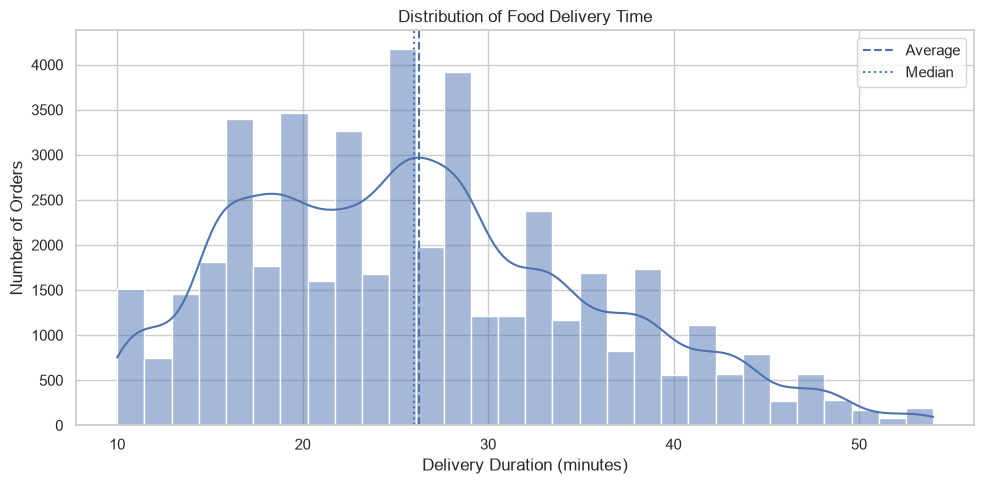

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=analysis_df,
    x="delivery_duration",
    bins=30,
    kde=True
)

plt.axvline(
    average_delivery,
    linestyle="--",
    label="Average"
)

plt.axvline(
    median_delivery,
    linestyle=":",
    label="Median"
)

plt.title("Distribution of Food Delivery Time")
plt.xlabel("Delivery Duration (minutes)")
plt.ylabel("Number of Orders")
plt.legend()

save_chart("01_delivery_distribution.png")

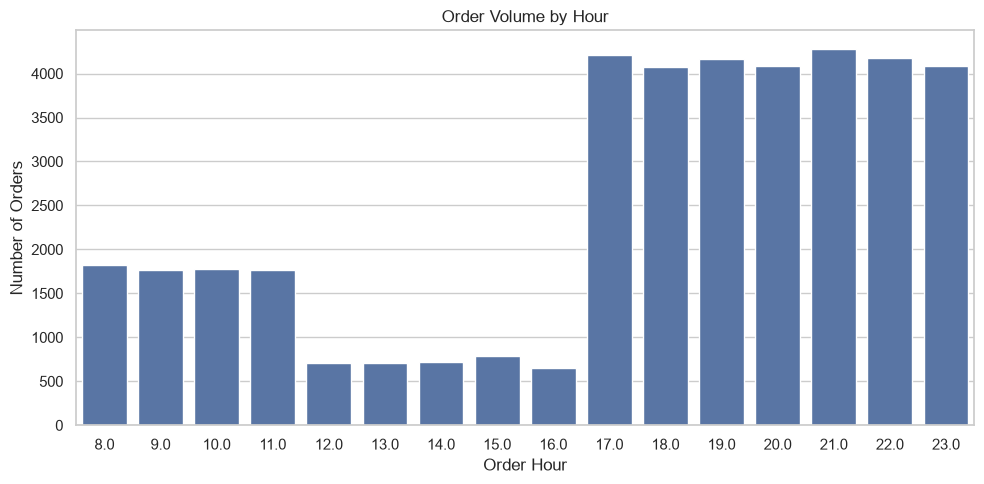

In [34]:
hourly_orders = (
    analysis_df.groupby("order_hour")
    .size()
    .reset_index(name="orders")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=hourly_orders,
    x="order_hour",
    y="orders"
)

plt.title("Order Volume by Hour")
plt.xlabel("Order Hour")
plt.ylabel("Number of Orders")

save_chart("02_orders_by_hour.png")

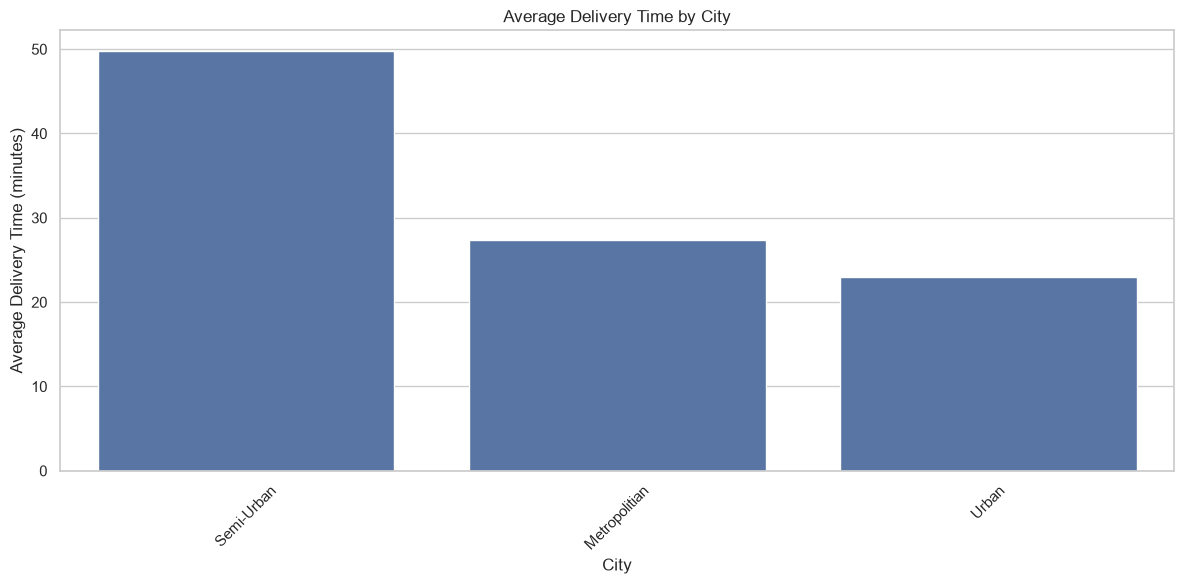

In [35]:
city_plot = (
    analysis_df.groupby("City")["delivery_duration"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=city_plot,
    x="City",
    y="delivery_duration"
)

plt.title("Average Delivery Time by City")
plt.xlabel("City")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=45)

save_chart("03_delivery_by_city.png")

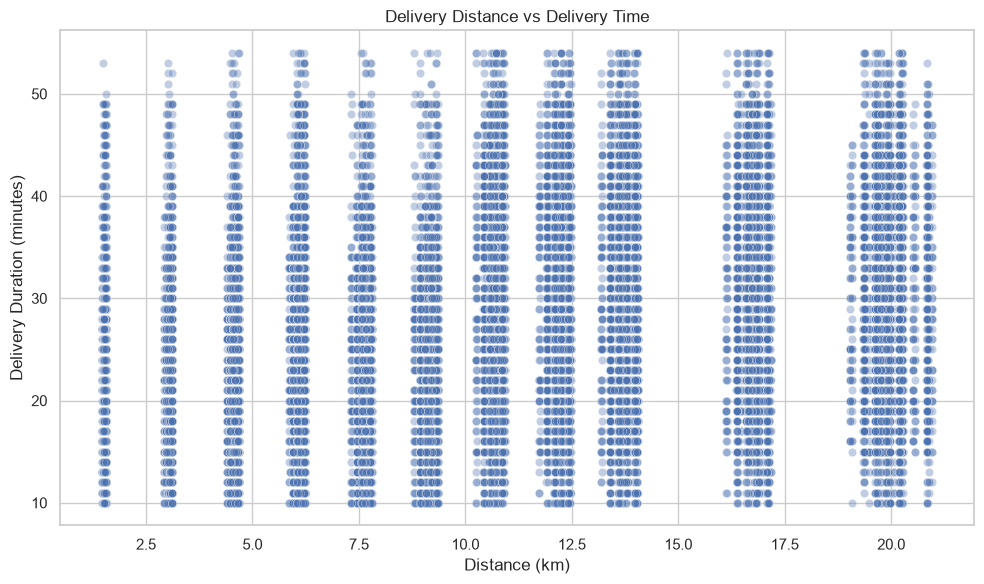

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_df,
    x="distance_km",
    y="delivery_duration",
    alpha=0.35
)

plt.title("Delivery Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Duration (minutes)")

save_chart("04_distance_vs_delivery.png")

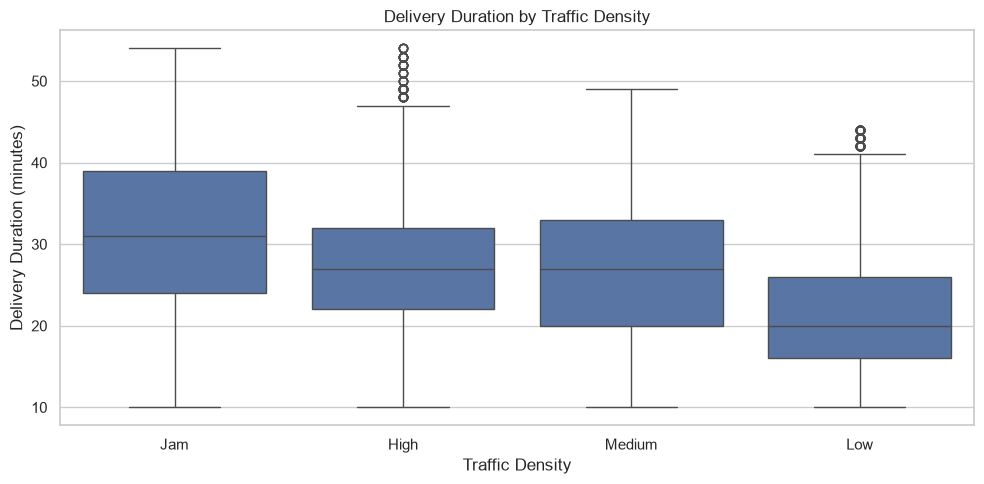

In [37]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=analysis_df,
    x="Road_traffic_density",
    y="delivery_duration"
)

plt.title("Delivery Duration by Traffic Density")
plt.xlabel("Traffic Density")
plt.ylabel("Delivery Duration (minutes)")

save_chart("05_delivery_by_traffic.png")

In [38]:
heatmap_data = analysis_df.pivot_table(
    index="Weatherconditions",
    columns="Road_traffic_density",
    values="delivery_duration",
    aggfunc="mean"
)

# Explicitly ensure numeric values
heatmap_data = heatmap_data.apply(
    pd.to_numeric,
    errors="coerce"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Average Delivery Time: Weather vs Traffic")
plt.xlabel("Traffic Density")
plt.ylabel("Weather")

save_chart("06_weather_traffic_heatmap.png")

KeyError: 'Weatherconditions'

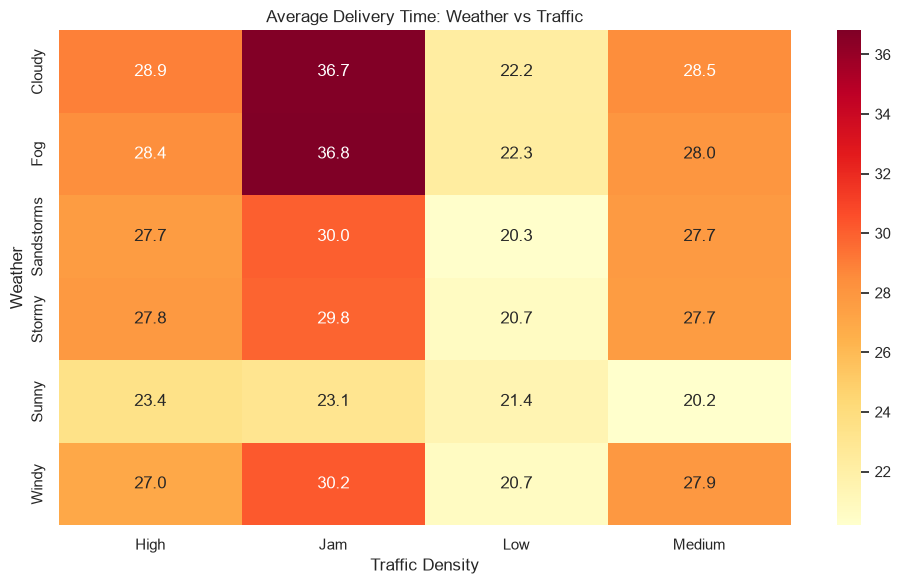

In [39]:
heatmap_data = analysis_df.pivot_table(
    index="Weather_conditions",
    columns="Road_traffic_density",
    values="delivery_duration",
    aggfunc="mean"
)

# Explicitly ensure numeric values
heatmap_data = heatmap_data.apply(
    pd.to_numeric,
    errors="coerce"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Average Delivery Time: Weather vs Traffic")
plt.xlabel("Traffic Density")
plt.ylabel("Weather")

save_chart("06_weather_traffic_heatmap.png")

In [40]:
Q1 = analysis_df["delivery_duration"].quantile(0.25)

Q3 = analysis_df["delivery_duration"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

analysis_df["is_outlier"] = (
    (analysis_df["delivery_duration"] < lower_bound) |
    (analysis_df["delivery_duration"] > upper_bound)
)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print(
    "Outliers:",
    analysis_df["is_outlier"].sum()
)

print(
    "Outlier percentage:",
    round(analysis_df["is_outlier"].mean() * 100, 2),
    "%"
)

Lower bound: -0.5
Upper bound: 51.5
Outliers: 270
Outlier percentage: 0.59 %


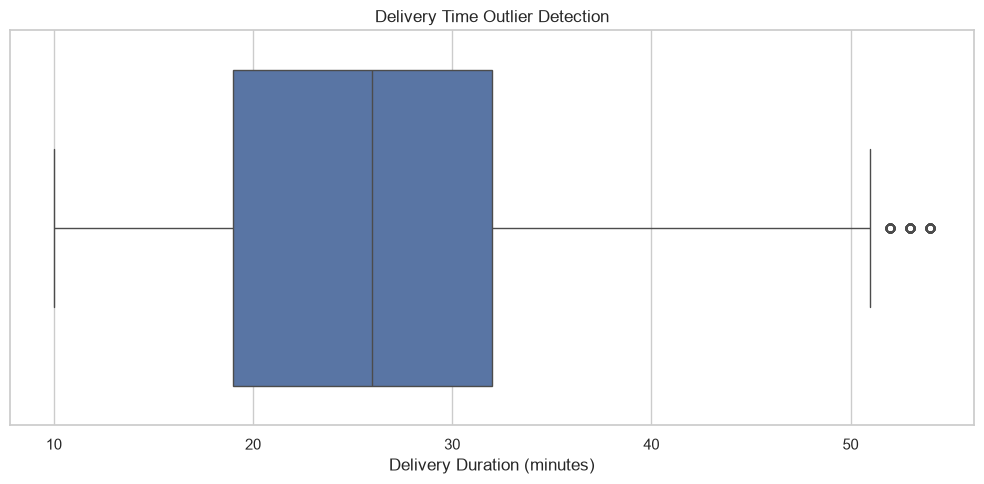

In [41]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=analysis_df["delivery_duration"]
)

plt.title("Delivery Time Outlier Detection")
plt.xlabel("Delivery Duration (minutes)")

save_chart("07_delivery_outliers.png")

In [42]:
slow_orders = (
    analysis_df.sort_values(
        "delivery_duration",
        ascending=False
    )
    .head(20)
)

display(
    slow_orders[
        [
            "delivery_duration",
            "distance_km",
            "Road_traffic_density",
            "Weatherconditions",
            "City",
            "Festival"
        ]
    ]
)

KeyError: "['Weatherconditions'] not in index"

In [43]:
slow_orders = (
    analysis_df.sort_values(
        "delivery_duration",
        ascending=False
    )
    .head(20)
)

display(
    slow_orders[
        [
            "delivery_duration",
            "distance_km",
            "Road_traffic_density",
            "Weather_conditions",
            "City",
            "Festival"
        ]
    ]
)

,delivery_duration,distance_km,Road_traffic_density,Weather_conditions,City,Festival
19179,54.0,16.368575,Jam,Cloudy,Semi-Urban,No
4640,54.0,16.852573,Jam,Windy,Metropolitian,No
12617,54.0,13.583079,Jam,Windy,Metropolitian,Yes
30189,54.0,NaN,Jam,Fog,Metropolitian,No
9079,54.0,10.867476,Jam,Fog,Metropolitian,Yes
5433,54.0,19.363385,Jam,Stormy,Urban,Yes
3702,54.0,9.326616,Jam,Sunny,Metropolitian,No
9163,54.0,9.088005,Jam,Sunny,Urban,Yes
37300,54.0,12.435538,Jam,Stormy,Metropolitian,No
45034,54.0,12.234822,Jam,Sandstorms,Metropolitian,No


In [44]:
y = analysis_df["delivery_duration"]

In [45]:
features = [
    "distance_km",
    "order_hour",
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Road_traffic_density",
    "Weather_conditions",
    "Type_of_order",
    "Type_of_vehicle",
    "Vehicle_condition",
    "multiple_deliveries",
    "Festival",
    "City"
]

In [46]:
from sklearn.model_selection import train_test_split

ml_df = analysis_df[
    features + ["delivery_duration"]
].copy()

X = ml_df[features]

y = ml_df["delivery_duration"]

categorical_features = [
    "Road_traffic_density",
    "Weather_conditions",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]

numerical_features = [
    "distance_km",
    "order_hour",
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Vehicle_condition",
    "multiple_deliveries"
]

# Use the same split for every model comparison
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 36467
Testing rows: 9117


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training complete.")

Random Forest training complete.


In [48]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE: 3.22
RMSE: 4.09
R2 Score: 0.8107


In [49]:
from catboost import CatBoostRegressor

cat_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostRegressor(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        verbose=False,
        random_seed=42
    ))
])

cat_model.fit(X_train, y_train)

cat_predictions = cat_model.predict(X_test)

cat_mae = mean_absolute_error(
    y_test,
    cat_predictions
)

cat_rmse = np.sqrt(
    mean_squared_error(y_test, cat_predictions)
)

cat_r2 = r2_score(y_test, cat_predictions)

print("CatBoost MAE:", round(cat_mae, 2))
print("CatBoost RMSE:", round(cat_rmse, 2))
print("CatBoost R2:", round(cat_r2, 4))

CatBoost MAE: 3.24
CatBoost RMSE: 4.09
CatBoost R2: 0.8106


In [50]:
model_comparison = pd.DataFrame({
    "Model": ["Random Forest", "CatBoost"],
    "MAE": [mae, cat_mae],
    "RMSE": [rmse, cat_rmse],
    "R2": [r2, cat_r2]
})

display(
    model_comparison.sort_values("MAE")
)

,Model,MAE,RMSE,R2
0,Random Forest,3.223822,4.086260,0.810708
1,CatBoost,3.236993,4.087508,0.810593


In [51]:
import joblib

best_model = (
    cat_model if cat_mae < mae else rf_model
)

joblib.dump(
    best_model,
    "../models/best_delivery_model.pkl"
)

print("Best model saved.")

Best model saved.


In [52]:
sample_order = pd.DataFrame([{
    "distance_km": 8.0,
    "order_hour": 20,
    "Delivery_person_Age": 28,
    "Delivery_person_Ratings": 4.5,
    "Road_traffic_density": "High",
    "Weather_conditions": "Sunny",
    "Type_of_order": "Snack",
    "Type_of_vehicle": "motorcycle",
    "Vehicle_condition": 2,
    "multiple_deliveries": 1,
    "Festival": "No",
    "City": "Metropolitian"
}])

prediction = best_model.predict(sample_order)

print(
    "Predicted delivery duration:",
    round(float(prediction[0]), 2),
    "minutes"
)

Predicted delivery duration: 15.65 minutes


In [53]:
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Food Delivery Predictor",
    page_icon="🍔",
    layout="centered"
)

st.title("Food Delivery Time Predictor")

st.write(
    "Enter order details to estimate delivery duration."
)

model = joblib.load("models/best_delivery_model.pkl")

distance = st.number_input(
    "Delivery distance (km)",
    min_value=0.1,
    max_value=50.0,
    value=8.0
)

order_hour = st.slider(
    "Order hour",
    min_value=0,
    max_value=23,
    value=20
)

age = st.number_input(
    "Delivery partner age",
    min_value=18,
    max_value=70,
    value=28
)

rating = st.slider(
    "Delivery partner rating",
    min_value=1.0,
    max_value=5.0,
    value=4.5,
    step=0.1
)

traffic = st.selectbox(
    "Traffic",
    ["Low", "Medium", "High", "Jam"]
)

weather = st.selectbox(
    "Weather",
    ["Sunny", "Cloudy", "Windy", "Stormy", "Fog"]
)

order_type = st.selectbox(
    "Order type",
    ["Snack", "Meal", "Drinks", "Buffet"]
)

vehicle = st.selectbox(
    "Vehicle",
    ["motorcycle", "scooter", "electric_scooter"]
)

vehicle_condition = st.selectbox(
    "Vehicle condition",
    [0, 1, 2, 3]
)

multiple_deliveries = st.selectbox(
    "Multiple deliveries",
    [0, 1, 2, 3]
)

festival = st.selectbox(
    "Festival",
    ["Yes", "No"]
)

city = st.selectbox(
    "City",
    ["Metropolitian", "Urban", "Semi-Urban"]
)

if st.button("Predict Delivery Time"):

    sample = pd.DataFrame([{
        "distance_km": distance,
        "order_hour": order_hour,
        "Delivery_person_Age": age,
        "Delivery_person_Ratings": rating,
        "Road_traffic_density": traffic,
        "Weather_conditions": weather,
        "Type_of_order": order_type,
        "Type_of_vehicle": vehicle,
        "Vehicle_condition": vehicle_condition,
        "multiple_deliveries": multiple_deliveries,
        "Festival": festival,
        "City": city
    }])

    prediction = model.predict(sample)[0]

    st.success(
        f"Estimated delivery time: {prediction:.1f} minutes"
    )

    st.caption(
        "This is a model estimate, not a guaranteed delivery time."
    )

2026-10-31 11:14:57.423 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:14:57.424 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:14:57.449 
  command:

    streamlit run /Users/anantrajput/Documents/Github/Food-Delivery-Time-and-Order-Analysis/.venv/lib/python3.14/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-10-31 11:14:57.449 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:14:57.449 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:14:57.449 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:14:57.449 Thread 'MainThread

FileNotFoundError: [Errno 2] No such file or directory: 'models/best_delivery_model.pkl'

2026-10-31 11:15:34.982 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:15:34.983 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:15:34.983 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:15:34.984 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:15:34.984 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:15:34.984 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:15:34.984 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


FileNotFoundError: [Errno 2] No such file or directory: 'models/best_delivery_model.pkl'

In [55]:
from pathlib import Path

model_path = Path("../models/best_delivery_model.pkl")

print("Model exists:", model_path.exists())
print("Expected location:", model_path.resolve())

Model exists: True
Expected location: /Users/anantrajput/Documents/Github/Food-Delivery-Time-and-Order-Analysis/models/best_delivery_model.pkl


In [56]:
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Food Delivery Predictor",
    page_icon="🍔",
    layout="centered"
)

st.title("Food Delivery Time Predictor")

st.write(
    "Enter order details to estimate delivery duration."
)
BASE_DIR = Path(__file__).resolve().parent

model = joblib.load(
    BASE_DIR / "models" / "best_delivery_model.pkl"
)

distance = st.number_input(
    "Delivery distance (km)",
    min_value=0.1,
    max_value=50.0,
    value=8.0
)

order_hour = st.slider(
    "Order hour",
    min_value=0,
    max_value=23,
    value=20
)

age = st.number_input(
    "Delivery partner age",
    min_value=18,
    max_value=70,
    value=28
)

rating = st.slider(
    "Delivery partner rating",
    min_value=1.0,
    max_value=5.0,
    value=4.5,
    step=0.1
)

traffic = st.selectbox(
    "Traffic",
    ["Low", "Medium", "High", "Jam"]
)

weather = st.selectbox(
    "Weather",
    ["Sunny", "Cloudy", "Windy", "Stormy", "Fog"]
)

order_type = st.selectbox(
    "Order type",
    ["Snack", "Meal", "Drinks", "Buffet"]
)

vehicle = st.selectbox(
    "Vehicle",
    ["motorcycle", "scooter", "electric_scooter"]
)

vehicle_condition = st.selectbox(
    "Vehicle condition",
    [0, 1, 2, 3]
)

multiple_deliveries = st.selectbox(
    "Multiple deliveries",
    [0, 1, 2, 3]
)

festival = st.selectbox(
    "Festival",
    ["Yes", "No"]
)

city = st.selectbox(
    "City",
    ["Metropolitian", "Urban", "Semi-Urban"]
)

if st.button("Predict Delivery Time"):

    sample = pd.DataFrame([{
        "distance_km": distance,
        "order_hour": order_hour,
        "Delivery_person_Age": age,
        "Delivery_person_Ratings": rating,
        "Road_traffic_density": traffic,
        "Weatherconditions": weather,
        "Type_of_order": order_type,
        "Type_of_vehicle": vehicle,
        "Vehicle_condition": vehicle_condition,
        "multiple_deliveries": multiple_deliveries,
        "Festival": festival,
        "City": city
    }])

    prediction = model.predict(sample)[0]

    st.success(
        f"Estimated delivery time: {prediction:.1f} minutes"
    )

    st.caption(
        "This is a model estimate, not a guaranteed delivery time."
    )

2026-10-31 11:19:02.748 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:19:02.749 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:19:02.749 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:19:02.750 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:19:02.750 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:19:02.750 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 11:19:02.750 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NameError: name '__file__' is not defined

In [57]:
from pathlib import Path

model_path = Path("../models/best_delivery_model.pkl")

print("Model exists:", model_path.exists())

Model exists: True


In [58]:
print(best_model.feature_names_in_)

['distance_km' 'order_hour' 'Delivery_person_Age'
 'Delivery_person_Ratings' 'Road_traffic_density' 'Weather_conditions'
 'Type_of_order' 'Type_of_vehicle' 'Vehicle_condition'
 'multiple_deliveries' 'Festival' 'City']


In [59]:
test_data = pd.DataFrame([{
    "distance_km": 8.0,
    "order_hour": 20,
    "Delivery_person_Age": 28,
    "Delivery_person_Ratings": rating,
    "Road_traffic_density": "Low",
    "Weather_conditions": "Sunny",
    "Type_of_order": "Snack",
    "Type_of_vehicle": "motorcycle",
    "Vehicle_condition": 2,
    "multiple_deliveries": 0,
    "Festival": "No",
    "City": "Urban"
} for rating in [1.0, 2.0, 3.0, 4.0, 5.0]])

test_data["Predicted_delivery_time"] = best_model.predict(test_data)

display(test_data[[
    "Delivery_person_Ratings",
    "Predicted_delivery_time"
]])

,Delivery_person_Ratings,Predicted_delivery_time
0,1.0,40.311988
1,2.0,40.311988
2,3.0,39.882702
3,4.0,31.063839
4,5.0,19.416057


In [60]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 2), "minutes")
print("RMSE:", round(rmse, 2), "minutes")
print("R2 Score:", round(r2, 4))

MAE: 3.22 minutes
RMSE: 4.09 minutes
R2 Score: 0.8107


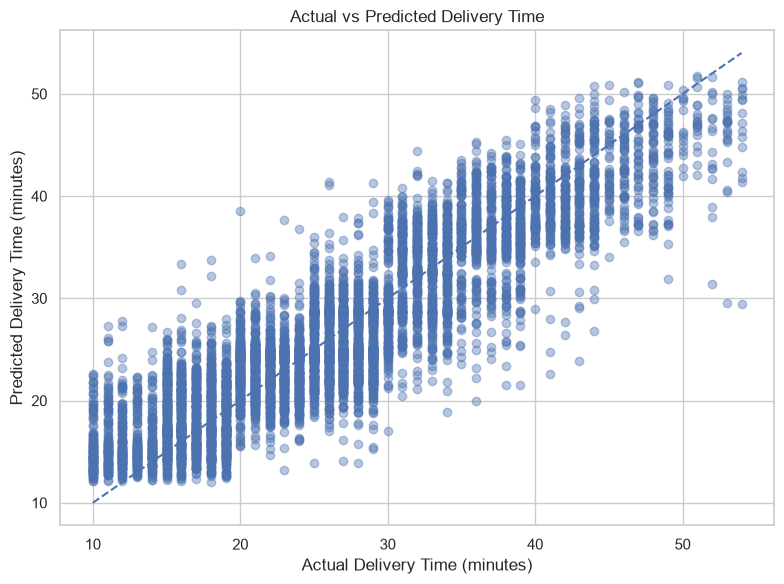

In [61]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")

plt.tight_layout()
plt.show()

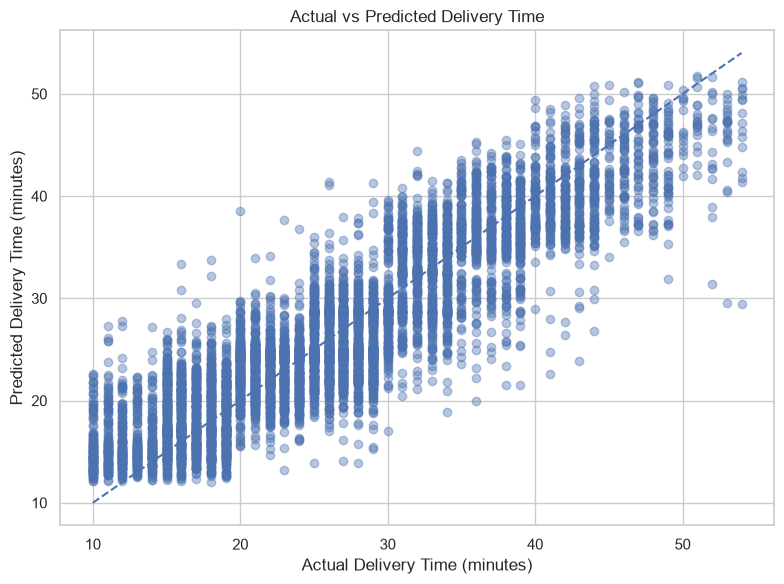

In [62]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")

plt.tight_layout()
plt.show()

In [63]:
import joblib
import json
from pathlib import Path

# Create models directory if it doesn't exist
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save trained model
joblib.dump(best_model, MODEL_DIR / "best_delivery_model.pkl")

# 2. Save model metadata
metadata = {
    "model_name": "Random Forest Regressor",
    "target": "Time_taken (min)",
    "features": list(best_model.feature_names_in_),
    "evaluation_metrics": {
        "MAE": 3.22,
        "RMSE": 4.09,
        "R2": 0.8107
    }
}

with open(MODEL_DIR / "model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

# 3. Save evaluation report
report = """
FOOD DELIVERY TIME PREDICTION
-----------------------------

Model: Random Forest Regressor

Evaluation Metrics:
MAE  : 3.22 minutes
RMSE : 4.09 minutes
R2   : 0.8107

Target:
Time_taken (min)

Features:
"""

report += "\n".join(
    f"- {feature}" for feature in best_model.feature_names_in_
)

with open(MODEL_DIR / "model_evaluation.txt", "w") as file:
    file.write(report)

print("All model files saved successfully!")

# Verify saved files
for file in MODEL_DIR.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

All model files saved successfully!
model_metadata.json - 0.51 KB
best_delivery_model.pkl - 106849.72 KB
model_evaluation.txt - 0.41 KB


In [1]:
from pathlib import Path

model_path = Path("../models/best_delivery_model.pkl")

print("Exists:", model_path.exists())
print("Size in bytes:", model_path.stat().st_size)
print("Size in MB:", model_path.stat().st_size / (1024 * 1024))

Exists: True
Size in bytes: 134
Size in MB: 0.0001277923583984375


In [2]:
from pathlib import Path

model_path = Path("../models/best_delivery_model.pkl")

print(model_path.read_text())

version https://git-lfs.github.com/spec/v1
oid sha256:cb2fce1e4f7b1e3314e39e430fa0c896db4a4ea19812aa84dddfafe6c3d7dbc2
size 109414115



In [3]:
print(best_model)

NameError: name 'best_model' is not defined

In [4]:
print(best_model)

NameError: name 'best_model' is not defined

In [5]:
from pathlib import Path

model_path = Path("../models/best_delivery_model.pkl")
print(model_path.read_text())

version https://git-lfs.github.com/spec/v1
oid sha256:cb2fce1e4f7b1e3314e39e430fa0c896db4a4ea19812aa84dddfafe6c3d7dbc2
size 109414115



In [6]:
for i, cell in enumerate(In[1:]):
    if any(word in cell for word in ["RandomForest", "best_model", "joblib.dump"]):
        print(f"\n--- Cell {i + 1} ---")
        print(cell[:1500])


--- Cell 3 ---
print(best_model)

--- Cell 4 ---
print(best_model)

--- Cell 6 ---
for i, cell in enumerate(In[1:]):
    if any(word in cell for word in ["RandomForest", "best_model", "joblib.dump"]):
        print(f"\n--- Cell {i + 1} ---")
        print(cell[:1500])


In [7]:
import joblib

model = joblib.load("../models/best_delivery_model.pkl")

print("Model recovered successfully!")
print(type(model))

Model recovered successfully!
<class 'sklearn.pipeline.Pipeline'>


In [8]:
import joblib

model = joblib.load("../models/best_delivery_model.pkl")

print("Model loaded successfully!")
print(type(model))
print("Features:", model.feature_names_in_)

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>
Features: ['distance_km' 'order_hour' 'Delivery_person_Age'
 'Delivery_person_Ratings' 'Road_traffic_density' 'Weather_conditions'
 'Type_of_order' 'Type_of_vehicle' 'Vehicle_condition'
 'multiple_deliveries' 'Festival' 'City']
